In [6]:
import numpy as np
import pandas as pd
from scipy.io import loadmat

In [7]:
data1 = loadmat('airu_train60_multi1_th50.mat') ## long

In [8]:
data = loadmat('test_results_hour_train10_multi1_th90.mat')

In [9]:
y_true = data['allY_Test'][:,:,:]
pred1 = data['allY_Fore'][:,:,:]


In [10]:
pred2 = data1['allY_Fore'][:,:,:]

In [11]:
error_mu = data['allRes_mu_train'] # residual for mu part

In [12]:
error_mu.shape

(240, 2, 183)

In [13]:
error = data['allRes_postgp_train'] # residual for whole model

In [14]:
error.shape

(240, 2, 183)

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert error_mu.shape == error.shape
n_train, n_loc, n_roll = error_mu.shape

last24_mu = error_mu[-24:, :, :]   # shape: (24, 2, 183)
last24_gp = error[-24:, :, :]      # shape: (24, 2, 183)

res_mu_loc1 = last24_mu[:, 0, :].reshape(-1, order="F")
res_mu_loc2 = last24_mu[:, 1, :].reshape(-1, order="F")

res_gp_loc1 = last24_gp[:, 0, :].reshape(-1, order="F")
res_gp_loc2 = last24_gp[:, 1, :].reshape(-1, order="F")

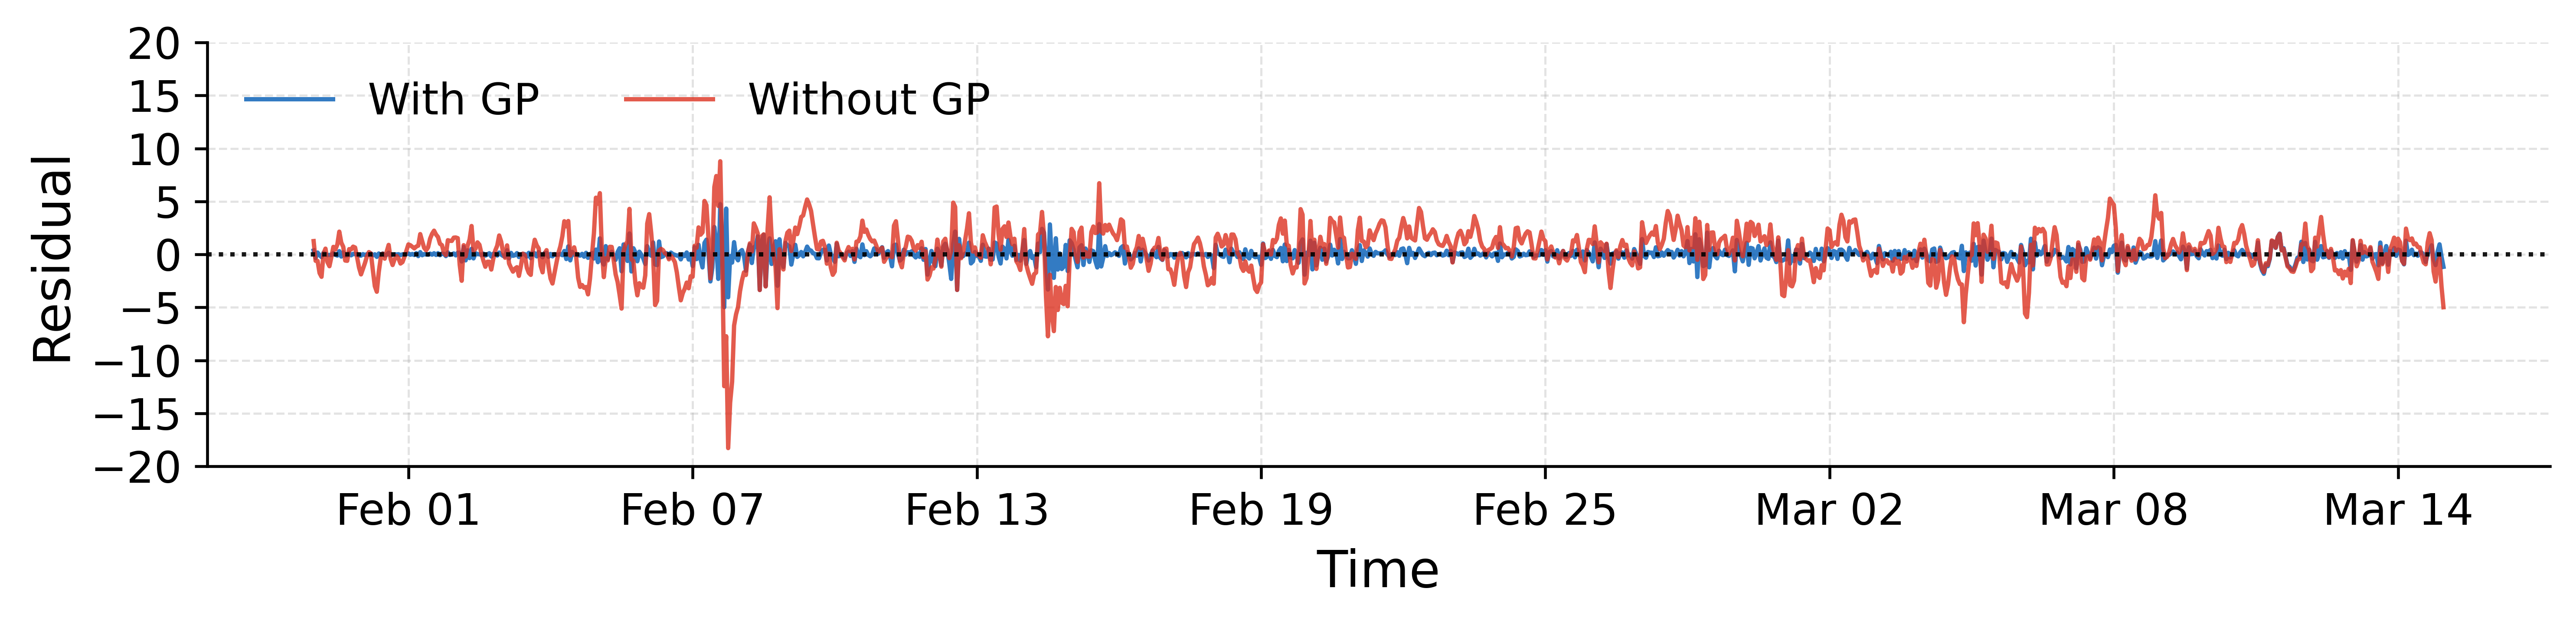

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# =========================
# 1. Prepare time index
# =========================
start_time = pd.Timestamp("2020-01-30 00:00")
n_hours = 45 * 24

time_index = pd.date_range(
    start=start_time,
    periods=n_hours,
    freq="h"
)

res1 = np.asarray(res_gp_loc1[:n_hours])
res2 = np.asarray(res_gp_loc2[:n_hours])
res3 = np.asarray(res_mu_loc1[:n_hours])
res4 = np.asarray(res_mu_loc2[:n_hours])

color_E05 = "#005AB5"   # strong blue
color_E06 = "#DC3220" 
# =========================
# 2. Plot
# =========================
fig, ax = plt.subplots(figsize=(10, 2.5), dpi=600)

# With GP: solid lines + circle markers
ax.plot(
    time_index,
    res1,
    color=color_E05,
    linestyle="-",
    linewidth=1.2,
    #marker="o",
    #markersize=2.2,
    #markevery=24,
    alpha = 0.8,
    label="With GP"
)

# ax.plot(
#     time_index,
#     res2,
#     color=color_E06,
#     linestyle="--",
#     linewidth=1,
#     #marker="s",
#     #markersize=2.2,
#     #markevery=24,
#     label="E06 with GP"
# )

# Without GP: dashed lines + different markers
ax.plot(
    time_index,
    res3,
    color=color_E06,
    linestyle="-",
    linewidth=1.2,
    #marker="^",
    #markersize=2.4,
    #markevery=24,
    alpha=0.8,
    label="Without GP"
)

# ax.plot(
#     time_index,
#     res4,
#     color=color_E06,
#     linestyle="-",
#     linewidth=1.2,
#     #marker="D",
#     #markersize=2.2,
#     #markevery=24,
#     alpha=0.4,
#     label="E06 without GP"
# )

# zero reference line
ax.axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1.2,
    alpha=0.9
)

# =========================
# 3. Symmetric y-axis
# =========================
ax.set_ylim(-20, 20)

# optional: add y ticks every 5 units
ax.set_yticks(np.arange(-20, 21, 5))

# =========================
# 4. Formatting
# =========================
ax.set_xlabel("Time", fontsize=14)
ax.set_ylabel("Residual", fontsize=14)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

# x-axis date format
ax.xaxis.set_major_locator(mdates.DayLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

plt.xticks(rotation=0, ha="center", fontsize=12)
plt.yticks(fontsize=12)

# remove top/right border
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    fontsize=12,
    ncol=2,
    loc="upper left"
)

plt.tight_layout()

# =========================
# 5. Save high-quality figure
# =========================
#plt.savefig("figure9_e05.png", dpi=600, bbox_inches="tight")
#plt.savefig("gp_training_residual_full_clear.pdf", bbox_inches="tight")

plt.show()

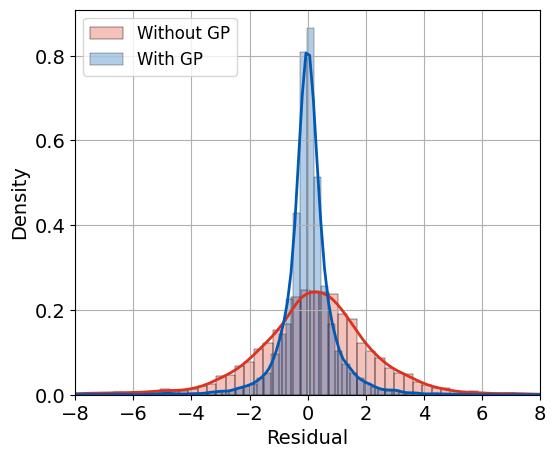

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ========= settings =========
loc = 0  # 0 or 1

res_mu = np.concatenate([res_mu_loc1,res_mu_loc2]).reshape(-1)
res_gp = np.concatenate([res_gp_loc1,res_gp_loc2]).reshape(-1)

# 去掉 nan
res_mu = res_mu[np.isfinite(res_mu)]
res_gp = res_gp[np.isfinite(res_gp)]

# ========= Histogram + KDE =========
plt.figure(figsize=(6,5))

sns.histplot(res_mu, bins=100, stat="density",
             color=color_E06, alpha=0.3, label="Without GP")

sns.kdeplot(res_mu, color=color_E06, linewidth=2)

sns.histplot(res_gp, bins=100, stat="density",
             color=color_E05, alpha=0.3, label="With GP")

sns.kdeplot(res_gp, color=color_E05, linewidth=2)

plt.xlabel("Residual", fontsize = 14)
plt.xlim([-8,8])
plt.ylabel("Density",fontsize = 14)
plt.xticks(fontsize = 14)
plt.yticks(fontsize = 14)
#plt.title("Residual Distribution (All Rolls Combined)")
plt.legend(loc = 'upper left',fontsize = 12)
plt.grid(True)
#plt.savefig('histogram.png',dpi = 600, bbox_inches = 'tight')
plt.show()